In [1]:
import pandas as pd
import numpy as np
import time
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix

# Load dataset
df = pd.read_csv('data/processed_reviews.csv')

# Double check class balance
print("Dataset balance:\n", df['label'].value_counts())

X = df['full_text']
y = df['label']

# 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

Dataset balance:
 label
1    29837
2    29837
0    29837
Name: count, dtype: int64


In [ ]:
# Cleaning and Vectorization
# Experimenting with n-grams (1,3) and increased features
# min_df=3 ignores terms that appear in fewer than 3 documents to reduce noise
tfidf = TfidfVectorizer(
    max_features=30000, 
    stop_words='english', 
    ngram_range=(1, 3), 
    lowercase=True,
    min_df=3
)

print("Vectorizing text with trigrams...")
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Display the final number of features created
print(f"Total features (unigrams, bigrams, trigrams): {X_train_tfidf.shape[1]}")

Vectorizing text...
Features created: 20000


In [3]:
print(f"Shape of training matrix: {X_train_tfidf.shape}")

Shape of training matrix: (71608, 20000)


In [ ]:
# Initialize and Train
svm = LinearSVC(C=0.1, random_state=42, max_iter=3000)

start_time = time.time()
svm.fit(X_train_tfidf, y_train)
print(f"Training took: {time.time() - start_time:.2f} seconds")

# Predict
y_pred = svm.predict(X_test_tfidf)

# Classification Report
print("\nSVM Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Neutral', 'Positive']))

Training took: 6.97 seconds

SVM Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.73      0.73      5967
     Neutral       0.63      0.59      0.61      5968
    Positive       0.78      0.82      0.80      5968

    accuracy                           0.71     17903
   macro avg       0.71      0.71      0.71     17903
weighted avg       0.71      0.71      0.71     17903



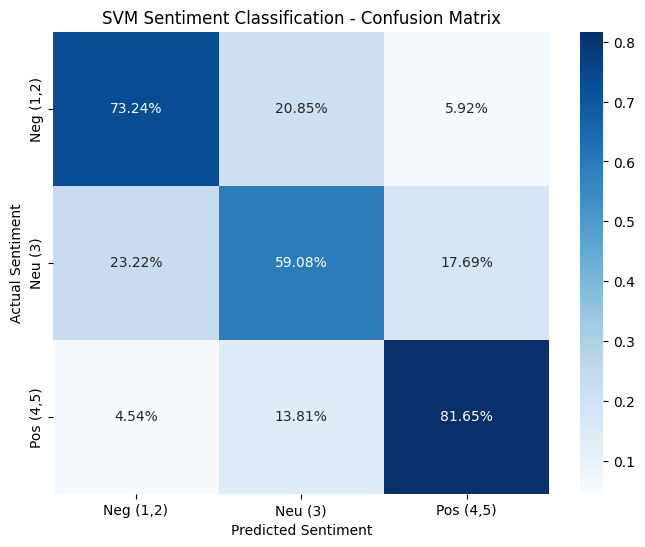

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Generate matrix
cm = confusion_matrix(y_test, y_pred)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] # Percentages

# Professional display
plt.figure(figsize=(8, 6))
sns.heatmap(cm_percent, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['Neg (1,2)', 'Neu (3)', 'Pos (4,5)'],
            yticklabels=['Neg (1,2)', 'Neu (3)', 'Pos (4,5)'])
plt.ylabel('Actual Sentiment')
plt.xlabel('Predicted Sentiment')
plt.title('SVM Sentiment Classification - Confusion Matrix')
plt.show()